In [12]:
import os, glob, h5py
import numpy as np, pandas as pd
import torch, torch.nn as nn, torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torchvision import models, transforms
import matplotlib.pyplot as plt
from tqdm.auto import tqdm

torch.manual_seed(42)
np.random.seed(42)
device = "cuda" if torch.cuda.is_available() else "cpu"
print("device:", device)

device: cuda


In [14]:
df = pd.read_csv(glob.glob("/kaggle/input/**/slice_info (1).csv", recursive=True)[0],
                 dtype={"slice_id": str, "pid": str})

paths = {os.path.splitext(os.path.basename(p))[0]: p
         for p in glob.glob("/kaggle/input/**/*.mat", recursive=True)}
df["path"] = df["slice_id"].map(paths)

print(df["path"].isna().sum(), "missing paths")   # expect 0
print(df.groupby("split").size())

0 missing paths
split
test      250
train    2449
val       365
dtype: int64


In [15]:
def load_resized(path):
    with h5py.File(path, "r") as f:
        img = np.array(f["cjdata"]["image"]).T.astype(np.float32)
    img = (img - img.min()) / (img.max() - img.min() + 1e-8)       # scale 0-1
    t = torch.from_numpy(img)[None, None]                          # shape 1,1,512,512
    t = F.interpolate(t, size=(224, 224), mode="bilinear",
                      antialias=True, align_corners=False)
    return t[0]                                                    # shape 1,224,224

X = torch.stack([load_resized(p) for p in tqdm(df["path"])])
y = torch.tensor(df["label"].to_numpy() - 1)                       # labels 1,2,3 -> 0,1,2
class_names = ["meningioma", "glioma", "pituitary"]

print(X.shape, X.min().item(), X.max().item())

  0%|          | 0/3064 [00:00<?, ?it/s]

torch.Size([3064, 1, 224, 224]) 0.0 0.9857247471809387


In [16]:
idx = {s: np.where(df["split"] == s)[0] for s in ["train", "val", "test"]}

MEAN = torch.tensor([0.485, 0.456, 0.406]).view(3, 1, 1)
STD  = torch.tensor([0.229, 0.224, 0.225]).view(3, 1, 1)
augment = transforms.Compose([transforms.RandomHorizontalFlip(),
                              transforms.RandomRotation(10)])

class SliceDataset(Dataset):
    def __init__(self, indices, train):
        self.indices, self.train = indices, train
    def __len__(self):
        return len(self.indices)
    def __getitem__(self, i):
        j = self.indices[i]
        x = X[j]
        if self.train:
            x = augment(x)                      # only training images get augmented
        x = (x.repeat(3, 1, 1) - MEAN) / STD    # 1 channel -> 3, then normalize
        return x, y[j]

train_dl = DataLoader(SliceDataset(idx["train"], True),  batch_size=32, shuffle=True, num_workers=2)
val_dl   = DataLoader(SliceDataset(idx["val"],   False), batch_size=64, num_workers=2)

In [17]:
model = models.resnet18(weights=models.ResNet18_Weights.DEFAULT)
model.fc = nn.Linear(model.fc.in_features, 3)
model = model.to(device)

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 199MB/s]


In [19]:
loss_fn = nn.CrossEntropyLoss()
opt = torch.optim.Adam(model.parameters(), lr=1e-4)

def evaluate(dl):
    model.eval()
    preds, trues, total_loss = [], [], 0.0
    with torch.no_grad():
        for xb, yb in dl:
            out = model(xb.to(device))
            total_loss += loss_fn(out, yb.to(device)).item() * len(yb)
            preds.append(out.argmax(1).cpu())
            trues.append(yb)
    preds, trues = torch.cat(preds), torch.cat(trues)
    return (preds == trues).float().mean().item(), total_loss / len(trues), preds.numpy(), trues.numpy()

EPOCHS = 8
history, best_val = [], 0.0
for epoch in range(EPOCHS):
    model.train()
    running = 0.0
    for xb, yb in train_dl:
        xb, yb = xb.to(device), yb.to(device)
        opt.zero_grad()
        loss = loss_fn(model(xb), yb)
        loss.backward()
        opt.step()
        running += loss.item() * len(yb)
    train_loss = running / len(train_dl.dataset)
    val_acc, val_loss, _, _ = evaluate(val_dl)
    history.append({"epoch": epoch + 1, "train_loss": train_loss,
                    "val_loss": val_loss, "val_acc": val_acc})
    if val_acc > best_val:
        best_val = val_acc
        torch.save(model.state_dict(), "/kaggle/working/resnet18_best.pth")
    print(f"epoch {epoch+1}: train loss {train_loss:.3f} | val loss {val_loss:.3f} | val acc {val_acc:.3f}")

epoch 1: train loss 0.022 | val loss 0.223 | val acc 0.926
epoch 2: train loss 0.030 | val loss 0.259 | val acc 0.929
epoch 3: train loss 0.039 | val loss 0.384 | val acc 0.915
epoch 4: train loss 0.039 | val loss 0.193 | val acc 0.948
epoch 5: train loss 0.013 | val loss 0.248 | val acc 0.937
epoch 6: train loss 0.012 | val loss 0.277 | val acc 0.934
epoch 7: train loss 0.005 | val loss 0.202 | val acc 0.953
epoch 8: train loss 0.007 | val loss 0.457 | val acc 0.929


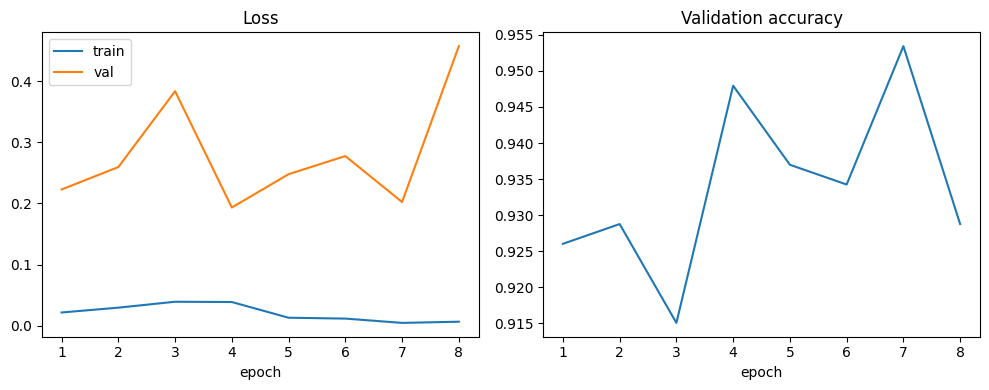

best validation accuracy: 0.953


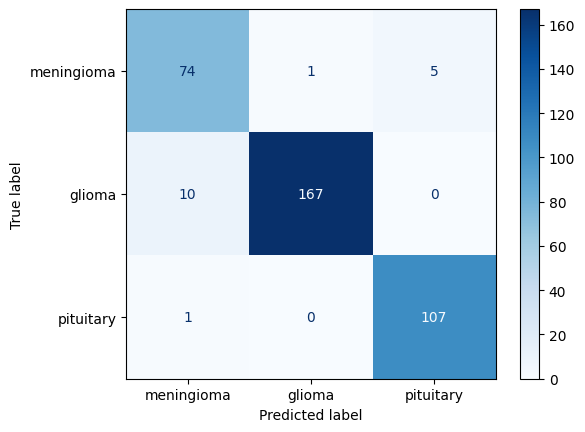

In [20]:
h = pd.DataFrame(history)
fig, ax = plt.subplots(1, 2, figsize=(10, 4))
ax[0].plot(h.epoch, h.train_loss, label="train"); ax[0].plot(h.epoch, h.val_loss, label="val")
ax[0].set_title("Loss"); ax[0].set_xlabel("epoch"); ax[0].legend()
ax[1].plot(h.epoch, h.val_acc); ax[1].set_title("Validation accuracy"); ax[1].set_xlabel("epoch")
plt.tight_layout()
plt.savefig("/kaggle/working/training_curves.png", dpi=150)
plt.show()

from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
model.load_state_dict(torch.load("/kaggle/working/resnet18_best.pth"))
val_acc, _, preds, trues = evaluate(val_dl)
print("best validation accuracy:", round(val_acc, 3))
cm = confusion_matrix(trues, preds)
ConfusionMatrixDisplay(cm, display_labels=class_names).plot(cmap="Blues")
plt.savefig("/kaggle/working/val_confusion.png", dpi=150)
plt.show()